In [21]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.ticker as mt
import pandas as pd
%matplotlib inline

In [13]:
BANKS = pd.DataFrame(
    {
        "bank": ["mbank"] * 8 + ["isobank"],
        "minimal_match": [
            0.97, 0.977, 0.978, 0.979, 0.98, 0.98775, 0.98775, 0.97, None,
        ],
        "covering_fraction": [
            0.9, 0.9, 0.9, 0.9, 0.9, 0.6, 0.9, 0.99, None,
        ],
        "templates_M": [
            2.95, 4.52, 4.84, 5.33, 5.48, 2.49, 11.9, 24.7, 2.27,
        ],
        "coverage_ff097": [
            94.17, 96.19, 96.44, 97.28, 97.20, 92.49, 98.97, 99.50, 96.64,
        ],
        "coverage_mc_lt_1p4": [
            65.6, 74.3, 72.3, 77.5, 77.7, 57.1, 88.3, 92.3, 91.3,
        ],
        "worst_ff": [
            0.615, 0.547, 0.637, 0.787, 0.620, 0.640, 0.803, 0.859, 0.93,
        ],
        "note": [
            "paper setting", "", "", "", "", "", "", "",
            "paper bank; worst FF approx.",
        ],
    }
)

In [35]:
mbank = BANKS[BANKS["bank"] == "mbank"]
isobank = BANKS[BANKS["bank"] == "isobank"].iloc[0]

mbank

,bank,minimal_match,covering_fraction,templates_M,coverage_ff097,coverage_mc_lt_1p4,worst_ff,note
0,mbank,0.97000,0.90,2.95,94.17,65.6,0.615,paper setting
1,mbank,0.97700,0.90,4.52,96.19,74.3,0.547,
2,mbank,0.97800,0.90,4.84,96.44,72.3,0.637,
3,mbank,0.97900,0.90,5.33,97.28,77.5,0.787,
4,mbank,0.98000,0.90,5.48,97.20,77.7,0.620,
5,mbank,0.98775,0.60,2.49,92.49,57.1,0.640,
6,mbank,0.98775,0.90,11.90,98.97,88.3,0.803,
7,mbank,0.97000,0.99,24.70,99.50,92.3,0.859,


In [24]:
mbank_a = BANKS[(BANKS["bank"] == "mbank") & (BANKS["covering_fraction"] == 0.9)]
mbank_b = BANKS[(BANKS["bank"] == "mbank") & (BANKS["covering_fraction"] == 0.99)]
mbank_a

,bank,minimal_match,covering_fraction,templates_M,coverage_ff097,coverage_mc_lt_1p4,worst_ff,note
0,mbank,0.97000,0.9,2.95,94.17,65.6,0.615,paper setting
1,mbank,0.97700,0.9,4.52,96.19,74.3,0.547,
2,mbank,0.97800,0.9,4.84,96.44,72.3,0.637,
3,mbank,0.97900,0.9,5.33,97.28,77.5,0.787,
4,mbank,0.98000,0.9,5.48,97.20,77.7,0.620,
6,mbank,0.98775,0.9,11.90,98.97,88.3,0.803,


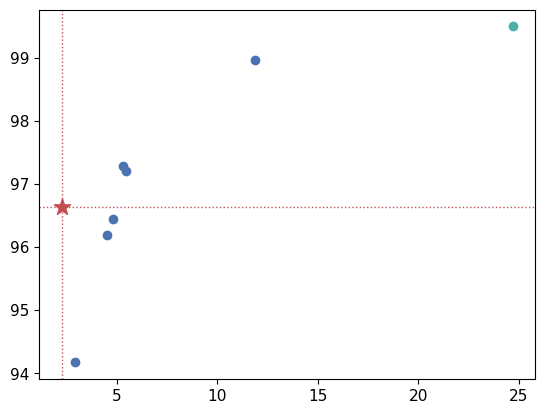

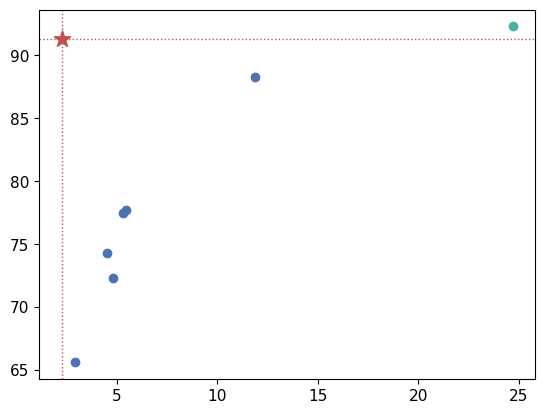

In [34]:

MBANK_COLOR_A = "#4C72B0"
MBANK_COLOR_B = "#4CB0A4"
ISOBANK_COLOR = "#C44E52"

for var in ["coverage_ff097", "coverage_mc_lt_1p4"]:
    plt.scatter(mbank_a["templates_M"], mbank_a[var], c=MBANK_COLOR_A, label='mbank, cf =0.9')
    plt.scatter(mbank_b["templates_M"], mbank_b[var], c=MBANK_COLOR_B, label='mbank, cf =0.99')
    plt.scatter(isobank["templates_M"], isobank[var], s=150, marker="*", c=ISOBANK_COLOR, label="isobank", zorder=4,)
    plt.axvline(isobank["templates_M"], c=ISOBANK_COLOR, zorder=-1, linestyle=':', lw=1)
    plt.axhline(isobank[var], c=ISOBANK_COLOR, zorder=-1, linestyle=':', lw=1)
    plt.show()

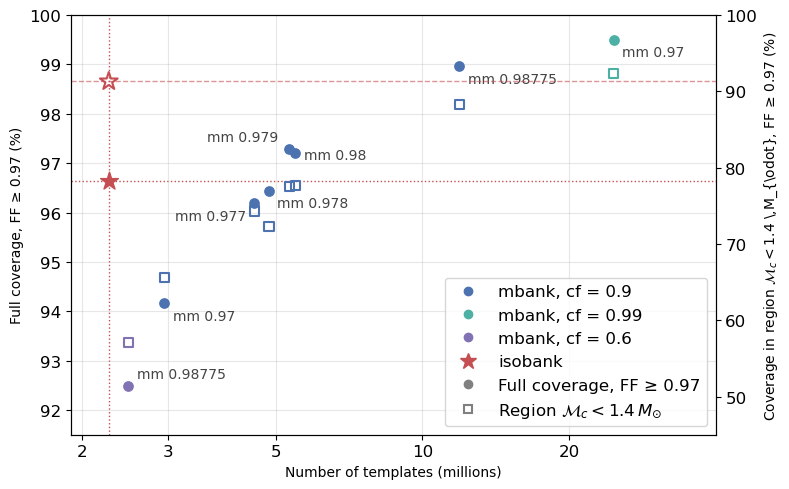

In [6]:
"""Plot bank size against coverage for the 5D template bank.

Compares the mbank minimal-match / covering-fraction sweep with isobank
in one panel: coverage at FF >= 0.97 on the left axis (filled markers)
and coverage for Mc < 1.4 on the right axis (open markers).
"""
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.lines import Line2D

# Templates in millions, coverages in percent.
BANKS = pd.DataFrame(
    {
        "bank": ["mbank"] * 8 + ["isobank"],
        "minimal_match": [
            0.97, 0.977, 0.978, 0.979, 0.98, 0.98775, 0.98775, 0.97, None,
        ],
        "covering_fraction": [
            0.9, 0.9, 0.9, 0.9, 0.9, 0.6, 0.9, 0.99, None,
        ],
        "templates_M": [
            2.95, 4.52, 4.84, 5.33, 5.48, 2.49, 11.9, 24.7, 2.27,
        ],
        "coverage_ff097": [
            94.17, 96.19, 96.44, 97.28, 97.20, 92.49, 98.97, 99.50, 96.64,
        ],
        "coverage_mc_lt_1p4": [
            65.6, 74.3, 72.3, 77.5, 77.7, 57.1, 88.3, 92.3, 91.3,
        ],
        "worst_ff": [
            0.615, 0.547, 0.637, 0.787, 0.620, 0.640, 0.803, 0.859, 0.93,
        ],
    }
)

is_mbank = BANKS["bank"] == "mbank"
mbank = BANKS[is_mbank]
mbank_a = BANKS[is_mbank & (BANKS["covering_fraction"] == 0.9)]
mbank_b = BANKS[is_mbank & (BANKS["covering_fraction"] == 0.99)]
mbank_c = BANKS[is_mbank & (BANKS["covering_fraction"] == 0.6)]
isobank = BANKS[BANKS["bank"] == "isobank"].iloc[0]

MBANK_COLOR_A = "#4C72B0"
MBANK_COLOR_B = "#4CB0A4"
MBANK_COLOR_C = "#8172B3"
ISOBANK_COLOR = "#C44E52"

GROUPS = [
    (mbank_a, MBANK_COLOR_A, "mbank, cf = 0.9"),
    (mbank_b, MBANK_COLOR_B, "mbank, cf = 0.99"),
    (mbank_c, MBANK_COLOR_C, "mbank, cf = 0.6"),
]

# Text offsets in points for labels that would otherwise overlap
LABEL_OFFSETS = {
    (0.979, 0.9): (-8, 6, "right"),
    (0.98, 0.9): (6, -4, "left"),
    (0.977, 0.9): (-6, -12, "right"),
    (0.978, 0.9): (6, -12, "left"),
    (0.98775, 0.6): (6, 6, "left"),
}

# Axis labels and tick labels at 12 pt, matching the paper font size
plt.rcParams.update({
    "axes.labelsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
})

fig, ax_ff = plt.subplots(figsize=(8, 5))
ax_mc = ax_ff.twinx()

for data, color, _ in GROUPS:
    # Left axis: coverage at FF >= 0.97, filled markers
    ax_ff.scatter(data["templates_M"], data["coverage_ff097"], c=color,
                  s=45, zorder=3)
    # Right axis: coverage for Mc < 1.4, open markers
    ax_mc.scatter(data["templates_M"], data["coverage_mc_lt_1p4"],
                  facecolors="none", edgecolors=color, s=45, lw=1.5,
                  marker="s", zorder=3)

ax_ff.scatter(isobank["templates_M"], isobank["coverage_ff097"], s=180,
              marker="*", c=ISOBANK_COLOR, zorder=4)
ax_mc.scatter(isobank["templates_M"], isobank["coverage_mc_lt_1p4"], s=180,
              marker="*", facecolors="none", edgecolors=ISOBANK_COLOR,
              lw=1.5, zorder=4)
ax_ff.axvline(isobank["templates_M"], c=ISOBANK_COLOR, zorder=-1,
              linestyle=":", lw=1)
ax_ff.axhline(isobank["coverage_ff097"], c=ISOBANK_COLOR, zorder=-1,
              linestyle=":", lw=1)
ax_mc.axhline(isobank["coverage_mc_lt_1p4"], c=ISOBANK_COLOR, zorder=-1,
              linestyle="--", lw=1, alpha=0.6)

# Minimal-match labels on the FF points
for _, row in mbank.iterrows():
    key = (row["minimal_match"], row["covering_fraction"])
    dx, dy, ha = LABEL_OFFSETS.get(key, (6, -12, "left"))
    ax_ff.annotate(f"mm {row['minimal_match']:g}",
                   (row["templates_M"], row["coverage_ff097"]),
                   xytext=(dx, dy), textcoords="offset points",
                   ha=ha, fontsize=10, color="#444444")

ax_ff.set_xscale("log")
ax_ff.set_xticks([2, 3, 5, 10, 20])
ax_ff.set_xticklabels(["2", "3", "5", "10", "20"])
ax_ff.minorticks_off()
ax_ff.set_xlim(1.9, 40)
# Different ranges on the two axes so filled and open markers of the
# same bank do not land on top of each other
ax_ff.set_ylim(91.5, 100)
ax_mc.set_ylim(45, 100)
ax_ff.set_xlabel("Number of templates (millions)")
ax_ff.set_ylabel("Full coverage, FF ≥ 0.97 (%)")
ax_mc.set_ylabel(r"Coverage in region $\mathcal{M}_c < 1.4$ \,M_{\odot}, FF ≥ 0.97 (%)")
ax_ff.grid(alpha=0.3)

# Legend: colour = bank / covering fraction, marker = which coverage
handles = [
    Line2D([], [], marker="o", ls="", color=color, label=label)
    for _, color, label in GROUPS
]
handles += [
    Line2D([], [], marker="*", ls="", ms=12, color=ISOBANK_COLOR,
           label="isobank"),
    Line2D([], [], marker="o", ls="", color="grey",
           label="Full coverage, FF ≥ 0.97"),
    Line2D([], [], marker="s", ls="", mfc="none", mec="grey", mew=1.5,
           label=r"Region $\mathcal{M}_c < 1.4 \,M_{\odot}$"),
]
ax_ff.legend(handles=handles, loc="lower right", fontsize=12)

fig.tight_layout()
fig.savefig("bank_size_vs_coverage.png", dpi=200)
fig.savefig("bank_size_vs_coverage.pdf")
plt.show()